# Week 8: Decision Trees (ID3)

## Student Practice Notebook

**Name:** D. Yashwanth

**Roll Number:** AP24110011685

**Date:** 09-10-2026

## Learning Objectives

After completing this lab, you will be able to:

- Compute entropy and information gain, by hand and in code
- Build an ID3 decision tree by hand on a small table (the exam-style problem)
- Fit and read a `DecisionTreeClassifier`
- Explain how tree depth controls overfitting (same idea as K in Week 7 and degree in Week 6)
- Explain how a tree differs from KNN: it asks questions about *features*, it does not measure *distance*

### Why this week matters
KNN (Week 7) classified by "who is closest?". A decision tree classifies by asking a chain of yes/no questions about features, and you can read the questions. That readability is why trees are used in credit, healthcare and fraud work, and why every ensemble in Unit V is built from them.


## Part 0 — Setup

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score

%matplotlib inline
np.random.seed(1)


## Part 1 — Entropy and Information Gain

**Entropy** measures how mixed a set of labels is: $H = -\sum p_i \log_2 p_i$. A pure set (all one class) has entropy 0. A 50/50 two-class set has entropy 1.

**Information gain** of splitting on an attribute = entropy before − weighted average entropy after. ID3 always picks the attribute with the highest gain.

### 1.1 Demo: entropy in code


In [4]:
def entropy(counts):
    counts = np.array(counts, dtype=float)
    p = counts[counts > 0] / counts.sum()
    return float(-np.sum(p * np.log2(p))) + 0.0

print('Pure set      [10, 0]:', entropy([10, 0]))
print('50/50 set     [5, 5] :', entropy([5, 5]))
print('Skewed set    [9, 1] :', entropy([9, 1]))


Pure set      [10, 0]: 0.0
50/50 set     [5, 5] : 1.0
Skewed set    [9, 1] : 0.4689955935892812


**Predict, then think:** which has higher entropy, a 70/30 split or a 90/10 split? Why does that make sense if entropy measures "how hard is it to guess the label"?

*Your answer:* A 70/30 split has higher entropy than a 90/10 split. Entropy measures the uncertainty in predicting a class label.In 70/30 split the classes are relatively balanced, so guessing the label is harder.In 90/10 split One class dominates, so guessing the majority class is more likely to be correct.(in 70/30 split: H ~ 0.881\) and in 90/10 split: (in 90/10 split:H~0.469)

### Student Practice — entropy of a split

A parent node has 8 Yes and 6 No. A candidate split sends 6 samples to the left child (6 Yes, 0 No) and 8 samples to the right child (2 Yes, 6 No). Compute the entropy of the parent and the information gain of the split.


In [5]:
# Write your answer here
parent_entropy = entropy([8, 6])
left_entropy = entropy([6, 0])
right_entropy = entropy([2, 6])
weighted_entropy = (6/14) * left_entropy + (8/14) * right_entropy
information_gain = parent_entropy - weighted_entropy
print(f"Parent Entropy: {parent_entropy:.4f}")
print(f"Left Child Entropy: {left_entropy:.4f}")
print(f"Right Child Entropy: {right_entropy:.4f}")
print(f"Weighted Entropy: {weighted_entropy:.4f}")
print(f"Information Gain: {information_gain:.4f}")

Parent Entropy: 0.9852
Left Child Entropy: 0.0000
Right Child Entropy: 0.8113
Weighted Entropy: 0.4636
Information Gain: 0.5216


## Part 2 — ID3 by Hand (the exam-style problem)

Classic 14-day "play tennis" table. Target: `Play`.


In [6]:
tennis = pd.DataFrame({
    'Outlook':     ['Sunny','Sunny','Overcast','Rain','Rain','Rain','Overcast','Sunny','Sunny','Rain','Sunny','Overcast','Overcast','Rain'],
    'Temperature': ['Hot','Hot','Hot','Mild','Cool','Cool','Cool','Mild','Cool','Mild','Mild','Mild','Hot','Mild'],
    'Humidity':    ['High','High','High','High','Normal','Normal','Normal','High','Normal','Normal','Normal','High','Normal','High'],
    'Wind':        ['Weak','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Strong'],
    'Play':        ['No','No','Yes','Yes','Yes','No','Yes','No','Yes','Yes','Yes','Yes','Yes','No'],
})
tennis


,Outlook,Temperature,Humidity,Wind,Play
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


In [7]:
def info_gain(df, attribute, target='Play'):
    total = entropy(df[target].value_counts())
    weighted = 0
    for value, subset in df.groupby(attribute):
        weighted += len(subset) / len(df) * entropy(subset[target].value_counts())
    return total - weighted

print('Root entropy:', round(entropy(tennis['Play'].value_counts()), 4))
print('Gain(Wind)  :', round(info_gain(tennis, 'Wind'), 4))


Root entropy: 0.9403
Gain(Wind)  : 0.0481


### Student Practice — find the root

1. Compute the information gain for `Outlook`, `Temperature` and `Humidity` using `info_gain`.
2. Which attribute does ID3 pick as the root?
3. For the root's branch that is **not** pure, which attribute would you split on next? (Filter `tennis` to that branch and recompute gains.)


In [8]:
# Write your answer here
attributes = ['Outlook', 'Temperature', 'Humidity']

for attr in attributes:
    print(f'Gain({attr}): {info_gain(tennis, attr):.4f}')

gains = {attr: info_gain(tennis, attr) for attr in attributes}
root = max(gains, key=gains.get)
print('\nRoot attribute:', root)

for value, subset in tennis.groupby(root):
    print(f'\nBranch: {root} = {value}')
    print(subset['Play'].value_counts())

    if subset['Play'].nunique() > 1:
        print('Information Gain for remaining attributes:')
        remaining = [a for a in attributes if a != root]

        for attr in remaining:
            print(f'Gain({attr}): {info_gain(subset, attr):.4f}')

        best_next = max(remaining, key=lambda a: info_gain(subset, a))
        print('Best next split:', best_next)

Gain(Outlook): 0.2467
Gain(Temperature): 0.0292
Gain(Humidity): 0.1518

Root attribute: Outlook

Branch: Outlook = Overcast
Play
Yes    4
Name: count, dtype: int64

Branch: Outlook = Rain
Play
Yes    3
No     2
Name: count, dtype: int64
Information Gain for remaining attributes:
Gain(Temperature): 0.0200
Gain(Humidity): 0.0200
Best next split: Temperature

Branch: Outlook = Sunny
Play
No     3
Yes    2
Name: count, dtype: int64
Information Gain for remaining attributes:
Gain(Temperature): 0.5710
Gain(Humidity): 0.9710
Best next split: Humidity


**Reflection:** `Overcast` became a leaf immediately. In your own words, why does a pure branch need no further splitting?

*Your answer:* A pure branch contains samples belonging to only one class. Since all samples in the Overcast branch have Play = Yes, there is no uncertainty (entropy = 0). Further splitting would not improve the prediction, so ID3 makes it a leaf node.


## Part 3 — `DecisionTreeClassifier` on Iris

Same Iris split as Week 7, so you can compare directly. Note: **trees do not need feature scaling**, because they compare a feature to a threshold, not distances between points. That is a real difference from KNN.


Test accuracy: 0.9555555555555556


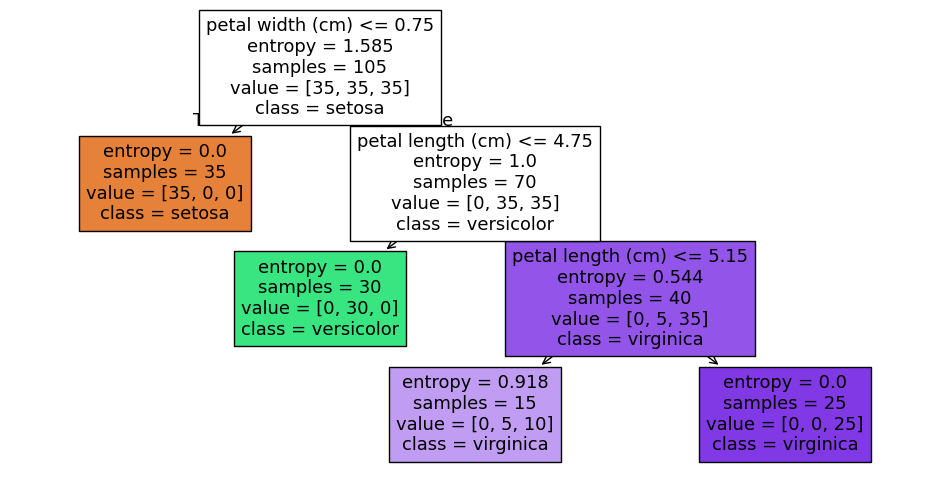

In [9]:
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

tree = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=1)
tree.fit(X_train, y_train)
print('Test accuracy:', accuracy_score(y_test, tree.predict(X_test)))

plt.figure(figsize=(12, 6))
plot_tree(tree, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)
plt.show()


### Student Practice — depth sweep

Sweep `max_depth` from 1 to 15. Record train and test accuracy for each, plot both, and report the depth with the best test accuracy.


Depth  1: Train Accuracy = 0.6667, Test Accuracy = 0.6667
Depth  2: Train Accuracy = 0.9524, Test Accuracy = 0.9556
Depth  3: Train Accuracy = 0.9524, Test Accuracy = 0.9556
Depth  4: Train Accuracy = 0.9524, Test Accuracy = 0.9333
Depth  5: Train Accuracy = 0.9714, Test Accuracy = 0.9778
Depth  6: Train Accuracy = 0.9810, Test Accuracy = 0.9778
Depth  7: Train Accuracy = 0.9810, Test Accuracy = 0.9778
Depth  8: Train Accuracy = 0.9905, Test Accuracy = 0.9778
Depth  9: Train Accuracy = 1.0000, Test Accuracy = 0.9778
Depth 10: Train Accuracy = 1.0000, Test Accuracy = 0.9778
Depth 11: Train Accuracy = 1.0000, Test Accuracy = 0.9778
Depth 12: Train Accuracy = 1.0000, Test Accuracy = 0.9778
Depth 13: Train Accuracy = 1.0000, Test Accuracy = 0.9778
Depth 14: Train Accuracy = 1.0000, Test Accuracy = 0.9778
Depth 15: Train Accuracy = 1.0000, Test Accuracy = 0.9778


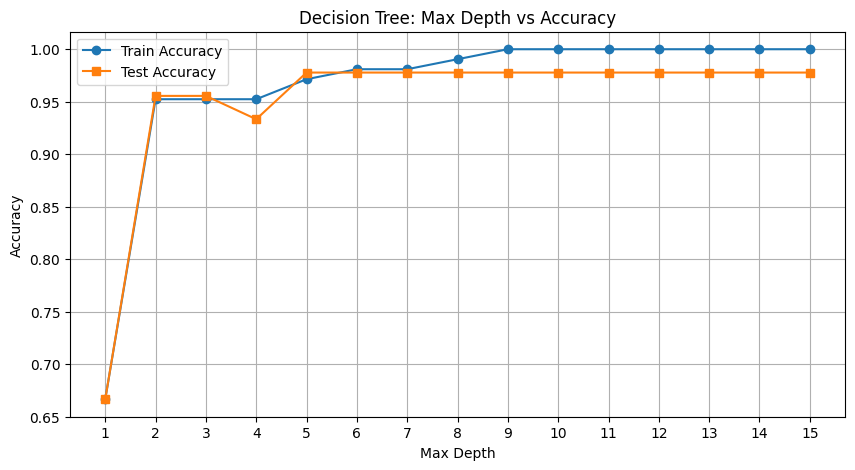


Best depth: 5
Best test accuracy: 0.9778


In [11]:
# Write your answer here
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

depths = range(1, 16)
train_acc = []
test_acc = []

for depth in depths:
    tree = DecisionTreeClassifier(criterion='entropy', max_depth=depth, random_state=1)
    tree.fit(X_train, y_train)

    train_acc.append(accuracy_score(y_train, tree.predict(X_train)))
    test_acc.append(accuracy_score(y_test, tree.predict(X_test)))

    print(f"Depth {depth:2d}: Train Accuracy = {train_acc[-1]:.4f}, "
          f"Test Accuracy = {test_acc[-1]:.4f}")

plt.figure(figsize=(10, 5))
plt.plot(depths, train_acc, marker='o', label='Train Accuracy')
plt.plot(depths, test_acc, marker='s', label='Test Accuracy')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.title('Decision Tree: Max Depth vs Accuracy')
plt.xticks(list(depths))
plt.legend()
plt.grid(True)
plt.show()

best_index = test_acc.index(max(test_acc))
print(f"\nBest depth: {list(depths)[best_index]}")
print(f"Best test accuracy: {test_acc[best_index]:.4f}")

**Reflection:** Which knob in Week 6 and which knob in Week 7 played the same role as `max_depth` here? What happens at each extreme?

*Your answer:* In Week 6, the k value in K-Nearest Neighbors (KNN) played a similar role, and in Week 7, the polynomial degree in polynomial regression played a similar role to max_depth.


# Mini Project A: Digits, Again (Image Track — continuing from Week 7)

Last week KNN reached about 98% on the digits dataset. Now fit a decision tree on the **same split** and ask two new questions: how does it compare, and **which pixels does the tree actually use?**


In [12]:
digits = load_digits()
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    digits.data, digits.target, test_size=0.3, random_state=1, stratify=digits.target)

# KNN baseline from Week 7 (scaled, K=3)
sc = StandardScaler().fit(Xd_train)
knn = KNeighborsClassifier(n_neighbors=3).fit(sc.transform(Xd_train), yd_train)
print('KNN  test accuracy:', accuracy_score(yd_test, knn.predict(sc.transform(Xd_test))))


KNN  test accuracy: 0.9796296296296296


### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on the **unscaled** `Xd_train`. Print test accuracy. (Why is no scaling needed?)

Ans: Decision Trees split features using threshold comparisons, such as pixel_20 <= 5. Scaling generally does not change the ordering of feature values, so it is not required for Decision Trees.

2. Try `max_depth` values 3, 6, 10 and report test accuracy for each.
3. Take `tree.feature_importances_` (64 values), reshape to 8×8 and show it with `plt.imshow`. Which region of the image does the tree rely on?

Ans: The tree generally relies more on the central region of the 8×8 image, where the main strokes of the digits are located. These pixels help distinguish between different digits. feature_importances_ heatmap. Brighter or hotter pixels indicate greater importance, while darker pixels contribute less to the tree's decisions.

Decision Tree test accuracy: 0.8814814814814815
Max depth 3: Test accuracy = 0.5296
Max depth 6: Test accuracy = 0.8537
Max depth 10: Test accuracy = 0.8796


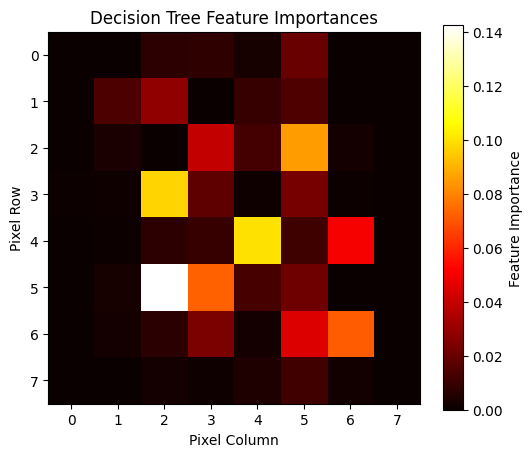

In [15]:
# Write your answer here
digits = load_digits()

Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    digits.data, digits.target,
    test_size=0.3, random_state=1, stratify=digits.target
)

tree = DecisionTreeClassifier(criterion='entropy', random_state=1)
tree.fit(Xd_train, yd_train)

print("Decision Tree test accuracy:", accuracy_score(yd_test, tree.predict(Xd_test)))

for depth in [3, 6, 10]:
    tree_depth = DecisionTreeClassifier(
        criterion='entropy', max_depth=depth, random_state=1
    )
    tree_depth.fit(Xd_train, yd_train)

    accuracy = accuracy_score(yd_test, tree_depth.predict(Xd_test))
    print(f"Max depth {depth}: Test accuracy = {accuracy:.4f}")

importance = tree.feature_importances_.reshape(8, 8)

plt.figure(figsize=(6, 5))
plt.imshow(importance, cmap='hot', interpolation='nearest')
plt.colorbar(label='Feature Importance')
plt.title('Decision Tree Feature Importances')
plt.xlabel('Pixel Column')
plt.ylabel('Pixel Row')
plt.show()

**Reflection:** Is the tree more or less accurate than KNN on digits? Offer one reason, using what the importance map shows you.

*Your answer:* The Decision Tree is generally less accurate than KNN on the Digits dataset. KNN uses distances between entire pixel patterns, while the tree relies on selected important pixels, as shown by the feature-importance map. Ignoring less important pixels can cause the tree to lose useful information for distinguishing similar digits.

# Mini Project B: Reading a Tree on Text (NLP Track — continuing from Week 7)

Same six labeled sentences and same bag-of-words vectors as Week 7. A tree gives you something KNN cannot: **the words it chose to split on.**


In [14]:
sentences = [
    'the cricket team won the match',
    'the batsman scored a century today',
    'chop the onions and boil the pasta',
    'add salt and simmer the curry',
    'the new phone has a faster processor',
    'the laptop battery lasts all day',
]
labels = ['sports', 'sports', 'cooking', 'cooking', 'tech', 'tech']

vocab = sorted(set(w for s in sentences for w in s.lower().split()))

def to_vector(sentence, vocab):
    words = sentence.lower().split()
    return np.array([words.count(w) for w in vocab])

X_text = np.array([to_vector(s, vocab) for s in sentences])


### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on `X_text`, `labels`.
2. Print the tree with `export_text(tree, feature_names=vocab)`. Which words does it split on?
3. Predict the topic of `'the striker scored a goal'` and of your own ambiguous sentence from Week 7.


In [17]:
# Write your answer here
tree = DecisionTreeClassifier(criterion='entropy', random_state=1)
tree.fit(X_text, labels)

print(export_text(tree, feature_names=vocab))

test_sentences = [
    'the striker scored a goal',
    'the player watched the game on television'
]

X_test_text = np.array([to_vector(s, vocab) for s in test_sentences])
predictions = tree.predict(X_test_text)

for sentence, prediction in zip(test_sentences, predictions):
    print(f"Sentence: {sentence}")
    print(f"Predicted topic: {prediction}\n")

|--- and <= 0.50
|   |--- has <= 0.50
|   |   |--- laptop <= 0.50
|   |   |   |--- class: sports
|   |   |--- laptop >  0.50
|   |   |   |--- class: tech
|   |--- has >  0.50
|   |   |--- class: tech
|--- and >  0.50
|   |--- class: cooking

Sentence: the striker scored a goal
Predicted topic: sports

Sentence: the player watched the game on television
Predicted topic: sports



Decision Tree splits on these three words:
1. and — the root node. If and > 0.50, predict cooking; otherwise, continue.
2. has — if and <= 0.50 and has > 0.50, predict tech.
3. laptop — if both and <= 0.50 and has <= 0.50, check laptop: if present, predict tech; otherwise, predict sports.

**Reflection:** If you added 3 more sentences per topic, would you expect the same split words? What does that tell you about trusting a tree trained on very little data?

*Your answer:* No, I would not necessarily expect the same split words. Adding more sentences could change which words provide the highest Information Gain, resulting in a different tree structure. This shows that a tree trained on very little data can be unstable and may learn patterns specific to the training examples rather than general rules. Therefore, we need more representative data to build a reliable model that generalizes well to unseen sentences.


## Summary

| What we did | Why it matters |
|---|---|
| Entropy and information gain | The rule ID3 uses to choose every split |
| ID3 by hand on the tennis table | Exam-style problem, show your working |
| `DecisionTreeClassifier` and depth sweep | Third version of the bias-variance knob (degree, K, depth) |
| Mini A: digits | Tree vs KNN on the same data, plus which pixels matter |
| Mini B: text | A tree you can read, and why tiny data makes it fragile |

**Next week:** Naive Bayes, a probabilistic classifier. Same digits and sentences again.
